In [ ]:
# enable automatic reloading of the notebook
%load_ext autoreload
%autoreload 2

# Tutorial: creating and comparing graph and timeseries embeddings
The following notebook provides a demonstration how to create and compare embeddings from a timeseries and graphs created from this timeseries with different methods.

In [1]:
import os, sys
sys.path.append("/var/scratch/sdu/ts2g2")

import warnings
warnings.filterwarnings("ignore")

import utils
from visualization import draw_g
from pipeline import T2G2Pipeline

# strategies
from strategies.view import get_view_strategy
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.merge import (
    get_link_nodes_strategy_builder,
    get_link_multigraph_strategy_builder,
)
from strategies.merge.strategy_linking_graph import StrategyLinkingGraphByValueWithinRange


# Accessing data
We first get path to the data.

In [2]:

# ---------- paths & data ----------
apple_path = os.path.join(os.getcwd(), "apple", "APPLE.csv")
ts_data = utils.CsvFile(apple_path, "Close").from_csv()


Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f7a904ec440>
Number of dimensions: 1; total windows: 1


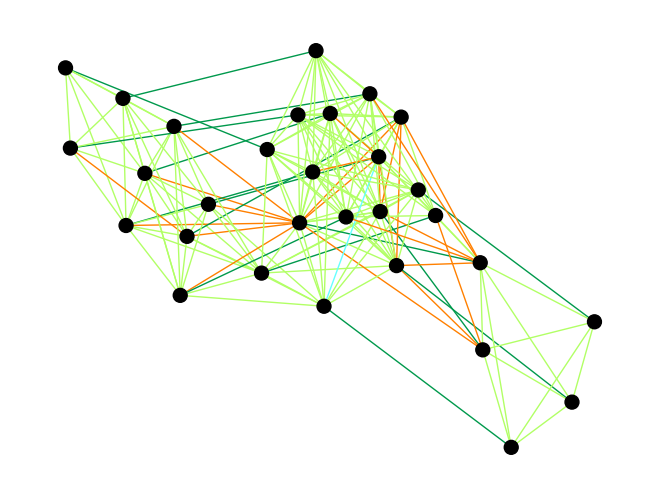

In [3]:

# ========== 1) Natural Visibility + add edges + link-within-graph ==========
# view: slice [60, 90)
view_nv = get_view_strategy("slice")(start_index=60, end_index=90)

# ts->graph: natural visibility with limit=1
nv_builder  = get_ts2g_strategy_builder(method="natural_visibility")
nv_strategy = nv_builder().with_limit(1).get_strategy()

# link within graph: by_value + seasonalities
ln_builder = get_link_nodes_strategy_builder()
link_nodes = ln_builder().by_value(StrategyLinkingGraphByValueWithinRange(2)).seasonalities(15)

pipeline_nv = T2G2Pipeline()
(
    pipeline_nv
        .load_timeseries(ts_data)
        .viewing(view_nv)
        .to_graph(nv_strategy)
        .add_edge(0, 2)                      # equivalent to TimeGraph.add_edge(0,2)
        .add_edge(13, 21, weight=17)         # equivalent to TimeGraph.add_edge(13,21, weight=17)
        .link_nodes_within_graphs(link_nodes)
)

G_nv = pipeline_nv.get_Graph()
draw_g(G_nv)



Applying viewing strategy: <strategies.view.views.SliceView object at 0x7f7925283590>
Number of dimensions: 1; total windows: 1


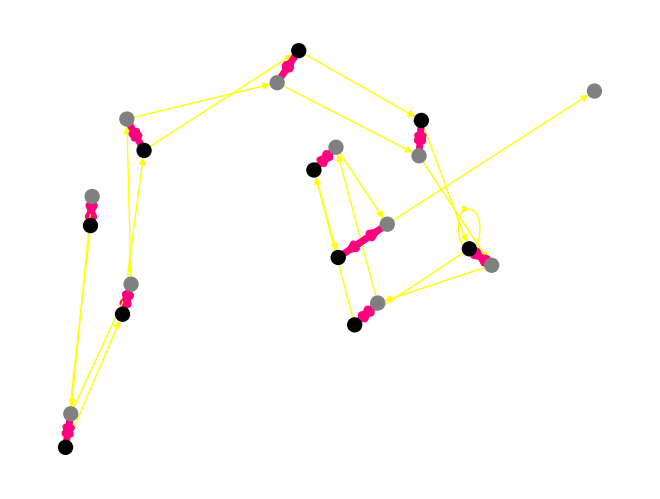

In [4]:

# ========== 2) Ordinal Partition (w=10, tau=5) + two slices + time co-occurrence ==========
# views: [60,120) and [120,180)
view_op_1 = get_view_strategy("slice")(start_index=60,  end_index=120)
view_op_2 = get_view_strategy("slice")(start_index=120, end_index=180)

# ts->graph: ordinal partition (w=10, tau=5)
op_builder  = get_ts2g_strategy_builder(method="ordinal")
op_strategy = op_builder(10, 5).get_strategy()

# multigraph linking: time_cooccurrence
mg_builder   = get_link_multigraph_strategy_builder()
link_multi   = mg_builder().time_cooccurrence()

pipeline_op = T2G2Pipeline()
(
    pipeline_op
        .load_timeseries(ts_data)
        .viewing(view_op_1)          # dim 1
        .add_view(view_op_2)         # dim 2 (parallel dimension, not a second pass)
        # .preprocess(hist)          # if you have a histogram preprocessor, insert here
        .to_graph(op_strategy)
        .link_graphs(link_multi)
)

G_op = pipeline_op.get_Graph()
draw_g(G_op)

Then we set parameters and train models for creating embeddings.

In [5]:
from strategies.embedding.ts2g2_embeddings import *
from strategies.embedding.utils import (
    get_random_walks_for_graph,
    train_graph_embedding_model,
)
from utils import CsvFile
apple_path = os.path.join(os.getcwd(), "apple", "APPLE.csv")
path = CsvFile(apple_path, "Close").from_csv()
embedding_size = 20
timegraph_natural_visibility = pipeline_nv.timegraph
timegraph_ordinal_partition = pipeline_op.timegraph
# to train graph embedding model, we need to provide multiple graphs. We chose arbitrary two as an example.
random_walks_visability_graph = get_random_walks_for_graph(timegraph_natural_visibility)
random_walks_ordin_part_graph = get_random_walks_for_graph(timegraph_ordinal_partition)

random_walks = random_walks_visability_graph + random_walks_ordin_part_graph
model_graph = train_graph_embedding_model(random_walks, embedding_size)

model_ts = TrainTimeseriesEmbeddingModel().train_model(path, embedding_size, epoch=20)

model_graph_visitor = VisitorGraphEmbeddingModelDoc2Vec(model_graph)
model_ts_visitor = VisitorTimeseriesEmbeddingModelTS2Vec(model_ts.get_model())
# VisitorTimeseriesEmbeddingModelTS2Vec model was made with the help of TS2Vec library (available on: https://github.com/zhihanyue/ts2vec.git; version: b0088e14a99706c05451316dc6db8d3da9351163)



AttributeError: 'numpy.ndarray' object has no attribute 'to_frame'

# Comparing embeddings
Now that we have set the parametersand trained our models, we can create and compare embeddings. Firstly, we need to create EmbeddingRanking object and give it models and strategies for timeseries to graph conversion, we want to compare. Then we add as many of the timeseries segments as we want and rank them. Because graph embeddings are created using random walk, we repeat this process multiple times and then calculate the average score.

In [ ]:
from scipy import stats

data = {
    'run': [], 
    'natural_visibility': [], 
    'horizontal_visibility': [], 
    'ordinal_partition': [], 
    'quantile': []
}

# Loop for embedding ranking process
i = 1
while i <= 5:
    # Generate embedding ranking
    x = (
        EmbeddingRanking(embedding_size)
        .set_embedding_models(model_ts_visitor, model_graph_visitor)
        .set_to_graph_strategies([
            BuildTimeseriesToGraphNaturalVisibilityStrategy(),
            BuildTimeseriesToGraphHorizontalVisibilityStrategy(),
            BuildTimeseriesToGraphOrdinalPartition(10, 5),
            BuildTimeseriesToGraphQuantile(4, 1)
        ])
        .add_timeseries(
            Timeseries(path).with_preprocessing(TimeseriesPreprocessingSegmentation(100, 200))
        )
        .add_timeseries(
            Timeseries(path).with_preprocessing(TimeseriesPreprocessingSegmentation(300, 400))
        )
        .embedding_ranking()
    )

    # Compute Kendall tau correlations for each strategy
    correlation = []
    for j in range(len(x.to_graph_methods)):
        tau_correlation = stats.kendalltau(x.ranking[0], x.ranking[j + 1]).correlation
        correlation.append(tau_correlation)
    
    # Add data for each run
    data['run'].append(i)
    data['natural_visibility'].append(correlation[0])
    data["horizontal_visibility"].append(correlation[1])
    data["ordinal_partition"].append(correlation[2])
    data["quantile"].append(correlation[3])

    i += 1

# Convert data to DataFrame and calculate average values
df = pd.DataFrame.from_dict(data)
average_values = df.mean()
print(average_values)

run                      3.0
natural_visibility      -0.2
horizontal_visibility    0.2
ordinal_partition        0.2
quantile                -0.2
dtype: float64
